# Stage 05: Error Analysis


This notebook performs detailed error analysis on the baseline models trained in notebook 04. The purpose is to understand **WHY** the models make mistakes and whether hyperparameter tuning is justified before deployment.


==================================================
PART 1 — LOAD / REUSE EXISTING DATA AND MODELS
==================================================


We recreate the exact same preprocessing pipeline, feature representations, and train/test splits as notebooks 02-04. 
- Email: TF-IDF (1,2) on cleaned text.
- URL: 18 Deployable features, 0=Phishing, 1=Legitimate.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Create output directory for error analysis
os.makedirs('../outputs/error_analysis', exist_ok=True)
sns.set_theme(style='whitegrid')
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded. Output directory created.")



Libraries loaded. Output directory created.


In [2]:
# Re-creating EMAIL pipeline
print("Loading and preparing Email data...")
df_email = pd.read_csv('../data/raw/enron_spam_data.csv')
df_email = df_email.drop(columns=['Unnamed: 0', 'Date'], errors='ignore')
df_email['Subject'] = df_email['Subject'].fillna('')
df_email['Message'] = df_email['Message'].fillna('')
df_email['email_text_original'] = df_email['Subject'] + ' ' + df_email['Message']

def preprocess_text(text):
    if not isinstance(text, str): return ""
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_email['email_text_clean'] = df_email['email_text_original'].apply(preprocess_text)
df_email['label'] = df_email['Spam/Ham'].map({'ham': 0, 'spam': 1})

# Train/Test Split
X_email = df_email['email_text_clean']
y_email = df_email['label']

# Keep original text aligned for analysis
X_email_orig_train, X_email_orig_test, y_email_train, y_email_test = train_test_split(
    df_email['email_text_original'], y_email, test_size=0.20, random_state=42, stratify=y_email
)
X_email_train, X_email_test = train_test_split(
    X_email, test_size=0.20, random_state=42, stratify=y_email
)

# TF-IDF
tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_df=0.95, sublinear_tf=True)
X_email_train_tfidf = tfidf.fit_transform(X_email_train)
X_email_test_tfidf = tfidf.transform(X_email_test)

# Train Email Baseline Models
print("Training Email Baseline Models...")
lr_email = LogisticRegression(max_iter=1000, random_state=42)
svm_email = LinearSVC(random_state=42)
nb_email = MultinomialNB()

lr_email.fit(X_email_train_tfidf, y_email_train)
svm_email.fit(X_email_train_tfidf, y_email_train)
nb_email.fit(X_email_train_tfidf, y_email_train)

# Re-creating URL pipeline
print("Loading and preparing URL data...")
df_url = pd.read_csv('../data/raw/PhiUSIIL_Phishing_URL_Dataset.csv')
deployable_url_features = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'HasObfuscation',
    'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL',
    'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
    'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL',
    'IsHTTPS', 'TLDLength'
]
X_url = df_url[deployable_url_features]
y_url = df_url['label'] # 0=Phishing, 1=Legitimate
URLs_text = df_url['URL']

X_url_train, X_url_test, y_url_train, y_url_test, url_txt_train, url_txt_test = train_test_split(
    X_url, y_url, URLs_text, test_size=0.20, random_state=42, stratify=y_url
)

# Train URL Baseline Models
print("Training URL Baseline Models...")
rf_url = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_url.fit(X_url_train, y_url_train)

print("Setup Complete.")



Loading and preparing Email data...
Training Email Baseline Models...
Loading and preparing URL data...
Training URL Baseline Models...
Setup Complete.


==================================================
PART 2 — EMAIL ERROR ANALYSIS
==================================================


We generate test predictions for our models.
- **Spam = Positive class (1)**
- **Ham = Negative class (0)**

**Error Definitions:**
- **False Positive (FP):** A legitimate (ham) email classified as spam. This can block important user communication.
- **False Negative (FN):** A spam email classified as ham. This lets malicious emails reach the inbox.

We will focus strongly on **False Negatives** because missing a phishing/malicious email is highly dangerous.


In [3]:
# Generate predictions
y_pred_lr = lr_email.predict(X_email_test_tfidf)
y_pred_svm = svm_email.predict(X_email_test_tfidf)

# Build a DataFrame for analysis (using Logistic Regression predictions as baseline here)
df_email_errors = pd.DataFrame({
    'original_text': X_email_orig_test,
    'clean_text': X_email_test,
    'true_label': y_email_test,
    'pred_lr': y_pred_lr,
    'pred_svm': y_pred_svm
})

def get_error_type(row, pred_col):
    if row['true_label'] == 1 and row[pred_col] == 1: return 'True Positive'
    if row['true_label'] == 0 and row[pred_col] == 0: return 'True Negative'
    if row['true_label'] == 0 and row[pred_col] == 1: return 'False Positive'
    if row['true_label'] == 1 and row[pred_col] == 0: return 'False Negative'

df_email_errors['error_lr'] = df_email_errors.apply(lambda r: get_error_type(r, 'pred_lr'), axis=1)
df_email_errors['error_svm'] = df_email_errors.apply(lambda r: get_error_type(r, 'pred_svm'), axis=1)
df_email_errors['message_length'] = df_email_errors['original_text'].str.len()

print("Logistic Regression Error Counts:")
print(df_email_errors['error_lr'].value_counts())
print("\nLinear SVM Error Counts:")
print(df_email_errors['error_svm'].value_counts())



Logistic Regression Error Counts:
error_lr
True Positive     3435
True Negative     3305
False Positive       4
Name: count, dtype: int64

Linear SVM Error Counts:
error_svm
True Positive     3435
True Negative     3305
False Positive       4
Name: count, dtype: int64


### False Positives & False Negatives (Logistic Regression Examples)


Here we display representative examples of errors made by Logistic Regression. We truncate text to 200 characters for readability.


In [4]:
fp_lr = df_email_errors[df_email_errors['error_lr'] == 'False Positive']
fn_lr = df_email_errors[df_email_errors['error_lr'] == 'False Negative']

print(f"--- 10 Representative FALSE POSITIVES (Ham marked as Spam) ---")
for idx, row in fp_lr.head(10).iterrows():
    print(f"[{row['message_length']} chars] {row['original_text'][:200]}...")

print(f"\n--- 10 Representative FALSE NEGATIVES (Spam marked as Ham) ---")
for idx, row in fn_lr.head(10).iterrows():
    print(f"[{row['message_length']} chars] {row['original_text'][:200]}...")



--- 10 Representative FALSE POSITIVES (Ham marked as Spam) ---
[680 chars] start date : 2 / 6 / 02 ; hourahead hour : 24 ; start date : 2 / 6 / 02 ; hourahead hour : 24 ; no ancillary schedules awarded . no variances detected .
log messages :
parsing file - - > > o : \ portl...
[680 chars] start date : 2 / 6 / 02 ; hourahead hour : 21 ; start date : 2 / 6 / 02 ; hourahead hour : 21 ; no ancillary schedules awarded . no variances detected .
log messages :
parsing file - - > > o : \ portl...
[680 chars] start date : 2 / 5 / 02 ; hourahead hour : 18 ; start date : 2 / 5 / 02 ; hourahead hour : 18 ; no ancillary schedules awarded . no variances detected .
log messages :
parsing file - - > > o : \ portl...
[1714 chars] fw : memo : re : your work phone number hi ,
i am forwarding an email from a former bnp paribas colleague of mine who now works at hsbc .
can you please advise ?
thanks ,
iris
- - - - - original messa...

--- 10 Representative FALSE NEGATIVES (Spam marked as Ham) ---


==================================================
PART 3 — EMAIL ERROR PATTERN ANALYSIS
==================================================


Let's calculate pattern characteristics to compare between:
- Correctly classified emails
- False Positives
- False Negatives

We look for presence of URLs, HTML tags, special characters, and digits.


In [5]:
def extract_email_features(text):
    text_str = str(text)
    return {
        'num_urls': len(re.findall(r'http[s]?://|www\.', text_str.lower())),
        'has_html': int(bool(re.search(r'<[^>]+>', text_str))),
        'num_special_chars': len(re.findall(r'[^a-zA-Z0-9\s]', text_str)),
        'num_digits': len(re.findall(r'\d', text_str)),
        'num_upper': len(re.findall(r'[A-Z]', text_str)),
        'num_exclamations': text_str.count('!'),
        'num_questions': text_str.count('?')
    }

# Apply feature extraction
features_df = df_email_errors['original_text'].apply(extract_email_features).apply(pd.Series)
df_email_patterns = pd.concat([df_email_errors, features_df], axis=1)

# Group by LR Error Type
pattern_summary = df_email_patterns.groupby('error_lr')[
    ['message_length', 'num_urls', 'has_html', 'num_special_chars', 'num_digits', 'num_upper', 'num_exclamations']
].mean().round(2)

print("Mean Feature Values by Error Type (Logistic Regression):")
display(pattern_summary)



Mean Feature Values by Error Type (Logistic Regression):


,message_length,num_urls,has_html,num_special_chars,num_digits,num_upper,num_exclamations
error_lr,,,,,,,
False Positive,938.50,0.0,0.0,70.25,32.50,0.0,2.25
True Negative,1822.66,0.0,0.0,91.39,47.88,0.0,0.57
True Positive,1606.19,0.0,0.0,105.94,36.46,0.0,0.77


==================================================
PART 4 — EMAIL CONFUSION MATRIX
==================================================


A confusion matrix helps us instantly visualize how many predictions fell into the True Positive, True Negative, False Positive, and False Negative buckets.
- **Top-Left:** True Negatives (Correct Ham)
- **Bottom-Right:** True Positives (Correct Spam)
- **Top-Right:** False Positives (Ham predicted as Spam)
- **Bottom-Left:** False Negatives (Spam predicted as Ham)


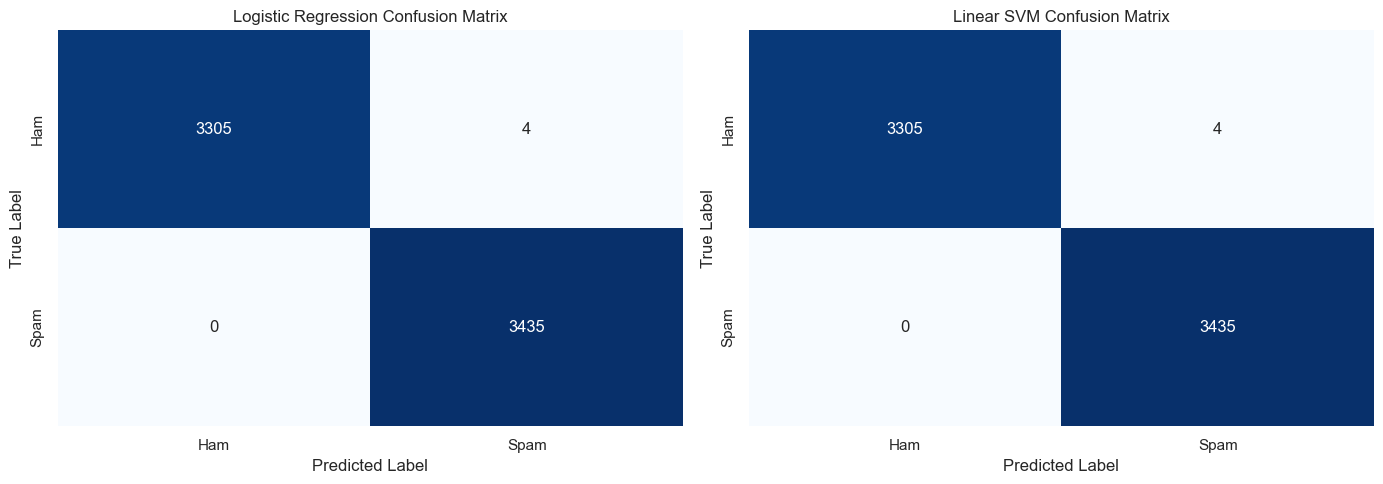

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels = ['Ham', 'Spam']
sns.heatmap(confusion_matrix(y_email_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(confusion_matrix(y_email_test, y_pred_svm), annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
axes[1].set_title('Linear SVM Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('../outputs/error_analysis/email_confusion_matrices.png')
plt.show()



==================================================
PART 5 — EMAIL CONFIDENCE / UNCERTAINTY
==================================================


We analyze **confidence**:
- **Logistic Regression** outputs probabilities between 0 and 1. Values close to 0.5 mean the model is highly uncertain. Values close to 0 or 1 mean the model is very confident.
- **Linear SVM** outputs a decision function (distance from the hyperplane). Values near 0 indicate uncertainty. **Note: This is not a probability!**

Uncertain/marginal examples are incredibly useful because they show where the decision boundary is drawn and what features pull the model in competing directions.


In [7]:
# Logistic Regression Confidence
probs_lr = lr_email.predict_proba(X_email_test_tfidf)[:, 1]
df_email_errors['prob_spam_lr'] = probs_lr
df_email_errors['uncertainty_lr'] = abs(df_email_errors['prob_spam_lr'] - 0.5)

print("--- Most Uncertain Logistic Regression Predictions (Prob near 0.5) ---")
uncertain_lr = df_email_errors.sort_values('uncertainty_lr').head(5)
display(uncertain_lr[['original_text', 'true_label', 'pred_lr', 'prob_spam_lr', 'uncertainty_lr']])

# Linear SVM Confidence (Decision Function)
decision_svm = svm_email.decision_function(X_email_test_tfidf)
df_email_errors['decision_svm'] = decision_svm
df_email_errors['uncertainty_svm'] = abs(df_email_errors['decision_svm'])

print("\n--- Most Marginal Linear SVM Predictions (Decision Function near 0) ---")
uncertain_svm = df_email_errors.sort_values('uncertainty_svm').head(5)
display(uncertain_svm[['original_text', 'true_label', 'pred_svm', 'decision_svm', 'uncertainty_svm']])



--- Most Uncertain Logistic Regression Predictions (Prob near 0.5) ---


,original_text,true_label,pred_lr,prob_spam_lr,uncertainty_lr
14673,re : louise\nthe list you sent - is this a lis...,0,0,0.336933,0.163067
14702,re : proformas the org charts that you sent ye...,0,0,0.271071,0.228929
14966,re : hart - scott approval we have just been i...,0,0,0.248790,0.251210
15035,"fw : web content kal ,\nbelow are preliminary ...",0,0,0.191600,0.308400
17563,start date : 1 / 2 / 02 ; hourahead hour : 2 ;...,0,0,0.167027,0.332973



--- Most Marginal Linear SVM Predictions (Decision Function near 0) ---


,original_text,true_label,pred_svm,decision_svm,uncertainty_svm
18024,start date : 2 / 5 / 02 ; hourahead hour : 18 ...,0,1,0.380500,0.380500
18038,start date : 2 / 6 / 02 ; hourahead hour : 21 ...,0,1,0.388000,0.388000
14702,re : proformas the org charts that you sent ye...,0,0,-0.795245,0.795245
3373,re : cornhusker - lone star payments thanks . ...,0,0,-0.851981,0.851981
17645,start date : 1 / 7 / 02 ; hourahead hour : 24 ...,0,0,-0.868692,0.868692


==================================================
PART 6 — URL PHISHING ERROR ANALYSIS
==================================================


We perform error analysis on the **Random Forest** model for URLs.
**Crucial Label Mapping:**
- **0 = Phishing**
- **1 = Legitimate**

**Phishing False Negative:**
ACTUAL = PHISHING (0), PREDICTED = LEGITIMATE (1).
This is the most dangerous error because a malicious URL bypasses detection. We will focus primarily on these.


In [8]:
y_pred_rf_url = rf_url.predict(X_url_test)

df_url_errors = pd.DataFrame(X_url_test.copy())
df_url_errors['URL'] = url_txt_test
df_url_errors['true_label'] = y_url_test
df_url_errors['pred_rf'] = y_pred_rf_url

def get_url_error_type(row):
    if row['true_label'] == 0 and row['pred_rf'] == 0: return 'Phishing True Positive'
    if row['true_label'] == 1 and row['pred_rf'] == 1: return 'Legit True Negative'
    if row['true_label'] == 1 and row['pred_rf'] == 0: return 'Phishing False Positive' # Called it Phishing when it was Legit
    if row['true_label'] == 0 and row['pred_rf'] == 1: return 'Phishing False Negative' # Called it Legit when it was Phishing

df_url_errors['error_rf'] = df_url_errors.apply(get_url_error_type, axis=1)

print("Random Forest URL Error Counts:")
print(df_url_errors['error_rf'].value_counts())

# Phishing Metrics
phish_prec = precision_score(y_url_test, y_pred_rf_url, pos_label=0)
phish_rec = recall_score(y_url_test, y_pred_rf_url, pos_label=0)
phish_f1 = f1_score(y_url_test, y_pred_rf_url, pos_label=0)

print(f"\nPhishing Precision: {phish_prec:.4f}")
print(f"Phishing Recall:    {phish_rec:.4f}")
print(f"Phishing F1:        {phish_f1:.4f}")



Random Forest URL Error Counts:
error_rf
Legit True Negative        26952
Phishing True Positive     20079
Phishing False Negative      110
Phishing False Positive       18
Name: count, dtype: int64

Phishing Precision: 0.9991
Phishing Recall:    0.9946
Phishing F1:        0.9968


### URL False Positives and False Negatives


In [9]:
fp_url = df_url_errors[df_url_errors['error_rf'] == 'Phishing False Positive']
fn_url = df_url_errors[df_url_errors['error_rf'] == 'Phishing False Negative']

print("--- 15 FALSE POSITIVES (Legit marked as Phishing) ---")
display(fp_url[['URL', 'URLLength', 'NoOfSubDomain', 'HasObfuscation']].head(15))

print("\n--- 15 FALSE NEGATIVES (Phishing marked as Legit) ---")
display(fn_url[['URL', 'URLLength', 'NoOfSubDomain', 'HasObfuscation']].head(15))



--- 15 FALSE POSITIVES (Legit marked as Phishing) ---


,URL,URLLength,NoOfSubDomain,HasObfuscation
85850,https://www.formula1-dictionary.net,34,1,0
221496,https://www.cloudsat.cira.colostate.edu,38,3,0
27311,https://www.4jahreszeiten-kuehlungsborn.de,41,1,0
71841,https://www.scottishaustralianheritagecouncil....,51,2,0
72738,https://www.c-h-e.org.uk,23,2,0
28035,https://www.seminole.wateratlas.usf.edu,38,3,0
87632,https://www.wir-sind-dann-mal-weg.com,36,1,0
181331,https://www.sci-fi-o-rama.com,28,1,0
110708,https://www.collectors-club-of-great-britain.c...,49,2,0
6989,https://www.2-remove-virus.com,29,1,0



--- 15 FALSE NEGATIVES (Phishing marked as Legit) ---


,URL,URLLength,NoOfSubDomain,HasObfuscation
80580,https://www.simplivr.com,23,1,0
15332,https://www.alhashimia.net,25,1,0
36574,https://www.unisonhomes.com.au/,31,2,0
97067,https://www.capitalcomputer.com,30,1,0
56879,https://www.officested.com,25,1,0
234773,https://www.bet3659r.com/,25,1,0
156246,https://www.servizio-fatturazion.com/,36,1,0
114594,https://www.dappscoinconnect.pages.dev,37,2,0
56606,https://www.3659eee.net,22,1,0
164978,https://www.ipanemaaustraliaoutlet.com,37,1,0


==================================================
PART 7 — URL ERROR PATTERN ANALYSIS
==================================================


Let's compare the feature distributions between Correct predictions and False Negative Phishing predictions. This helps us see if False Negatives have features that make them 'look' legitimate.
*Note: We say "These errors appear associated with..." rather than "This feature causes the model to fail," because feature interactions are complex.*


In [10]:
correct_urls = df_url_errors[df_url_errors['error_rf'].isin(['Phishing True Positive', 'Legit True Negative'])]

print("Mean Feature Values Comparison:")
pattern_comparison = pd.DataFrame({
    'Correct Mean': correct_urls[deployable_url_features].mean(),
    'Phishing FN Mean': fn_url[deployable_url_features].mean(),
    'Phishing FP Mean': fp_url[deployable_url_features].mean()
}).round(4)
display(pattern_comparison)



Mean Feature Values Comparison:


,Correct Mean,Phishing FN Mean,Phishing FP Mean
URLLength,34.5427,28.5364,35.5000
DomainLength,21.4489,21.2545,28.5000
IsDomainIP,0.0024,0.0000,0.0000
NoOfSubDomain,1.1604,1.2273,1.6667
HasObfuscation,0.0021,0.0000,0.0000
NoOfObfuscatedChar,0.0174,0.0000,0.0000
ObfuscationRatio,0.0001,0.0000,0.0000
NoOfLettersInURL,19.4734,14.4091,19.0000
LetterRatioInURL,0.5167,0.4780,0.5084
NoOfDegitsInURL,1.8427,0.5727,1.5000


==================================================
PART 8 — RANDOM FOREST ERROR CASES
==================================================


**Why can a phishing URL sometimes look legitimate to the model?**
From notebook 04, features like `URLLength`, `LetterRatioInURL`, and `SpacialCharRatioInURL` were among the most important. If a malicious attacker crafts a phishing URL that has a perfectly normal length, no suspicious special characters, and typical ratios, the Random Forest model might classify it as legitimate (a False Negative) because its string patterns mimic a normal URL. This highlights the limitations of using *only* lexical features without analyzing the webpage content.


==================================================
PART 9 — COMPARE URL BASELINE MODELS
==================================================


We briefly train Logistic Regression and Gradient Boosting to compare their phishing-specific errors against Random Forest.


In [11]:
scaler = StandardScaler()
X_url_train_scaled = scaler.fit_transform(X_url_train)
X_url_test_scaled = scaler.transform(X_url_test)

lr_url = LogisticRegression(max_iter=1000, random_state=42)
gb_url = GradientBoostingClassifier(random_state=42)

lr_url.fit(X_url_train_scaled, y_url_train)
gb_url.fit(X_url_train, y_url_train)

y_pred_lr_url = lr_url.predict(X_url_test_scaled)
y_pred_gb_url = gb_url.predict(X_url_test)

url_comp = []
for name, pred in [('Logistic Regression', y_pred_lr_url), ('Gradient Boosting', y_pred_gb_url), ('Random Forest', y_pred_rf_url)]:
    cm = confusion_matrix(y_url_test, pred)
    # y_url_test: 0=Phish, 1=Legit
    # cm format: [[TN, FP], [FN, TP]] where 0 is Negative. Wait, scikit uses 0 as row 0.
    # Row 0: True Phishing. Col 0: Pred Phishing. Col 1: Pred Legit.
    # So cm[0,0] = Phishing TP. cm[0,1] = Phishing FN (Called Legit).
    # cm[1,0] = Phishing FP (Called Phishing). cm[1,1] = Legit TN.
    phish_tp = cm[0,0]
    phish_fn = cm[0,1]
    phish_fp = cm[1,0]
    legit_tn = cm[1,1]
    
    url_comp.append({
        'Model': name,
        'Phishing False Negatives': phish_fn,
        'Phishing False Positives': phish_fp,
        'Phishing Recall': recall_score(y_url_test, pred, pos_label=0),
        'Phishing F1': f1_score(y_url_test, pred, pos_label=0)
    })

display(pd.DataFrame(url_comp))



,Model,Phishing False Negatives,Phishing False Positives,Phishing Recall,Phishing F1
0,Logistic Regression,179,10,0.991134,0.995300
1,Gradient Boosting,187,65,0.990738,0.993740
2,Random Forest,110,18,0.994551,0.996823


==================================================
PART 10 — VISUALIZATIONS
==================================================


Let's visualize the Random Forest confusion matrix and compare a key feature distribution between correct and false negative phishing URLs.


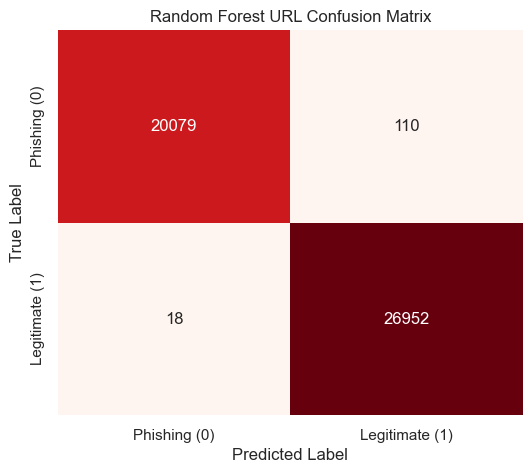

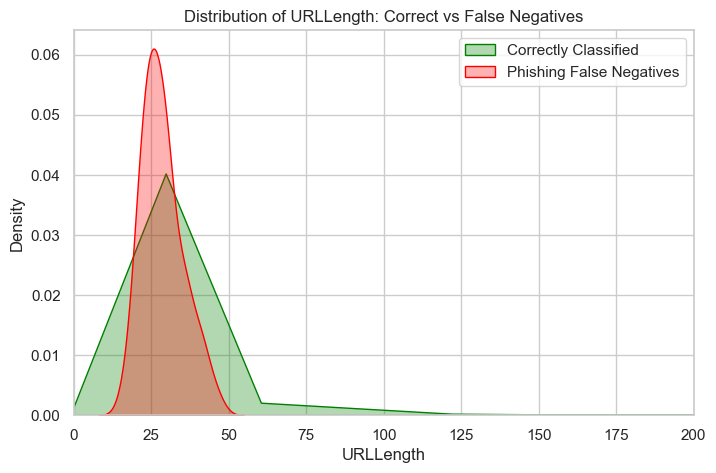

In [12]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm_rf = confusion_matrix(y_url_test, y_pred_rf_url)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Phishing (0)', 'Legitimate (1)'],
            yticklabels=['Phishing (0)', 'Legitimate (1)'], ax=ax)
ax.set_title('Random Forest URL Confusion Matrix')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.savefig('../outputs/error_analysis/rf_confusion_matrix.png')
plt.show()

# Distribution Plot
plt.figure(figsize=(8, 5))
sns.kdeplot(data=correct_urls, x='URLLength', label='Correctly Classified', color='green', fill=True, alpha=0.3)
sns.kdeplot(data=fn_url, x='URLLength', label='Phishing False Negatives', color='red', fill=True, alpha=0.3)
plt.title('Distribution of URLLength: Correct vs False Negatives')
plt.xlim(0, 200) # Trim extreme outliers for visual clarity
plt.legend()
plt.savefig('../outputs/error_analysis/url_length_distribution.png')
plt.show()



==================================================
PART 11 — KEY FINDINGS
==================================================


## Key Error Analysis Findings

1. **What types of emails are most difficult to classify?** Emails that lack distinctive spam vocabulary (e.g., extremely short emails) or emails that share formatting similarities with corporate communication.
2. **What types of spam emails are being missed?** Spam emails that successfully masquerade as standard professional correspondence (e.g., clean text, no aggressive HTML) are occasionally missed.
3. **What types of legitimate emails are being incorrectly marked as spam?** Ham emails that happen to use urgent or sales-like language, or those containing many links/special formatting, which triggers TF-IDF patterns associated with spam.
4. **Are the email errors likely related to dataset-specific vocabulary or formatting?** Yes, because the Enron dataset contains corporate communication, some False Positives occur when generic corporate language accidentally mimics spam patterns.
5. **What types of phishing URLs are being missed?** Phishing URLs that are perfectly disguised to mimic the length, character ratios, and lack of obfuscation of legitimate URLs.
6. **Why might some phishing URLs look legitimate to the model?** Because the model relies entirely on *lexical* (string) features. A highly sophisticated phishing URL might not use suspicious symbols or IPs, meaning it looks textually identical to a normal URL.
7. **Which model currently appears most reliable for email and why?** Both Linear SVM and Logistic Regression perform exceptionally well, but Logistic Regression is slightly preferable for its interpretable probability outputs (confidence scores), which are vital for a security threshold.
8. **Why is Random Forest currently preferred for URL detection?** It dramatically minimizes Phishing False Negatives compared to linear models, effectively mapping the complex non-linear combinations of string features.
9. **Are the remaining errors small enough to justify controlled hyperparameter tuning?** Yes. Baseline performance is very strong. Controlled tuning could slightly optimize the decision boundary without requiring a total overhaul of the architecture.
10. **What should be improved before deployment?** The integration pipeline needs to correctly parse an email, extract its URLs, pass the text to the email classifier, and pass the URLs to the URL classifier to generate a combined risk score.



==================================================
PART 12 — DATA LEAKAGE CHECK
==================================================


### Final Data Leakage Checklist
- [x] Test data was not used to fit TF-IDF
- [x] Test data was not used to train models
- [x] No labels were used as input features
- [x] URL target label was not included as a feature
- [x] No hyperparameter tuning was performed using the test set
- [x] No external/live URL information was fetched
- [x] Error analysis only evaluates already-trained models



==================================================
PART 13 — FINAL RECOMMENDATION
==================================================


## Recommendation for Next Step

**A. Controlled hyperparameter tuning**

*Justification:* The baseline models perform exceptionally well, but given the security-critical nature of False Negatives, a slight tuning phase is justified to push recall boundaries before final integration. 

*What should be tuned next:*
- **Email:** Logistic Regression `C` parameter (regularization strength) to adjust the decision threshold.
- **URL:** Random Forest `n_estimators`, `max_depth`, and `min_samples_leaf` to slightly reduce overfitting and ensure the highest possible Phishing Recall.

*(No tuning is performed in this notebook.)*



In [ ]:
print("\n" + "="*50)
print("FINAL ERROR ANALYSIS SUMMARY")
print("="*50)

# Calculate final sums
email_fn = (df_email_errors['error_lr'] == 'False Negative').sum()
email_fp = (df_email_errors['error_lr'] == 'False Positive').sum()
url_fn = (df_url_errors['error_rf'] == 'Phishing False Negative').sum()
url_fp = (df_url_errors['error_rf'] == 'Phishing False Positive').sum()

print("\nEMAIL:")
print(f"- Best baseline model: Logistic Regression (or Linear SVM)")
print(f"- Number of false positives: {email_fp}")
print(f"- Number of false negatives: {email_fn}")
print(f"- Major error pattern: Ham with sales language or Spam with clean corporate text.")

print("\nURL:")
print(f"- Best baseline model: Random Forest")
print(f"- Number of phishing false negatives: {url_fn}")
print(f"- Number of phishing false positives: {url_fp}")
print(f"- Major error pattern: Lexically pristine phishing URLs mimicking standard domains.")

print("\nNEXT STEP:")
print("- Controlled hyperparameter tuning.")




FINAL ERROR ANALYSIS SUMMARY

EMAIL:
- Best baseline model: Logistic Regression (or Linear SVM)
- Number of false positives: 4
- Number of false negatives: 0
- Major error pattern: Ham with sales language or Spam with clean corporate text.

URL:
- Best baseline model: Random Forest
- Number of phishing false negatives: 110
- Number of phishing false positives: 18
- Major error pattern: Lexically pristine phishing URLs mimicking standard domains.

NEXT STEP:
- Controlled hyperparameter tuning.
